In [1]:
from google.colab import drive
drive.mount('/drive')

path = '/drive/MyDrive/Magnetic Materials/'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Drive already mounted at /drive; to attempt to forcibly remount, call drive.mount("/drive", force_remount=True).


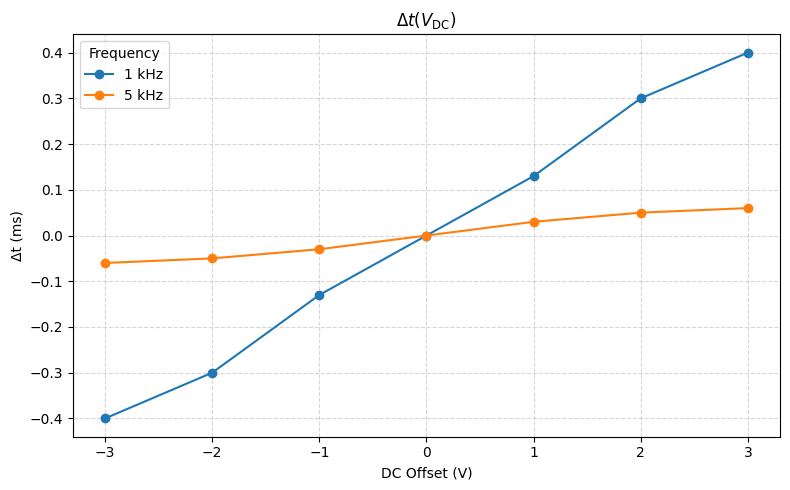

In [2]:
voltdc = [-3, -2, -1, 0, 1, 2, 3]
dt1khz = [-0.40, -0.30, -0.13, 0.00, 0.13, 0.30, 0.40]
dt5khz = [-0.06, -0.05, -0.03, 0.00, 0.03, 0.05, 0.06]

plt.figure(figsize=(8, 5))
plt.plot(voltdc, dt1khz, label='1 kHz', marker='o')
plt.plot(voltdc, dt5khz, label='5 kHz', marker='o')

plt.xlabel('DC Offset (V)')
plt.ylabel('Δt (ms)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.legend(title='Frequency')
plt.title(r'$Δt(V_{\mathrm{DC}})$')
plt.tight_layout()
plt.show()

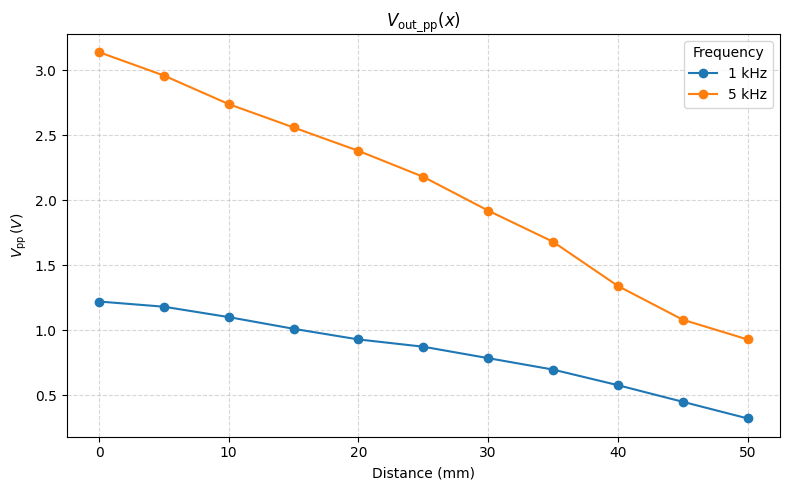

In [3]:
xmm = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
v1khz = [1.220, 1.180, 1.100, 1.010, 0.928, 0.872,
         0.784, 0.696, 0.576, 0.448, 0.320]
v5khz = [3.140, 2.960, 2.740, 2.560, 2.380, 2.180,
         1.920, 1.680, 1.340, 1.080, 0.928]

plt.figure(figsize=(8, 5))
plt.plot(xmm, v1khz, label='1 kHz', marker='o')
plt.plot(xmm, v5khz, label='5 kHz', marker='o')

plt.xlabel('Distance (mm)')
plt.ylabel(r'$V_{\mathrm{pp}}\,(V)$')
plt.grid(True, linestyle='--', alpha=0.5)

plt.legend(title='Frequency')
plt.title(r'$V_{\mathrm{out\_pp}}(x)$')
plt.tight_layout()
plt.show()

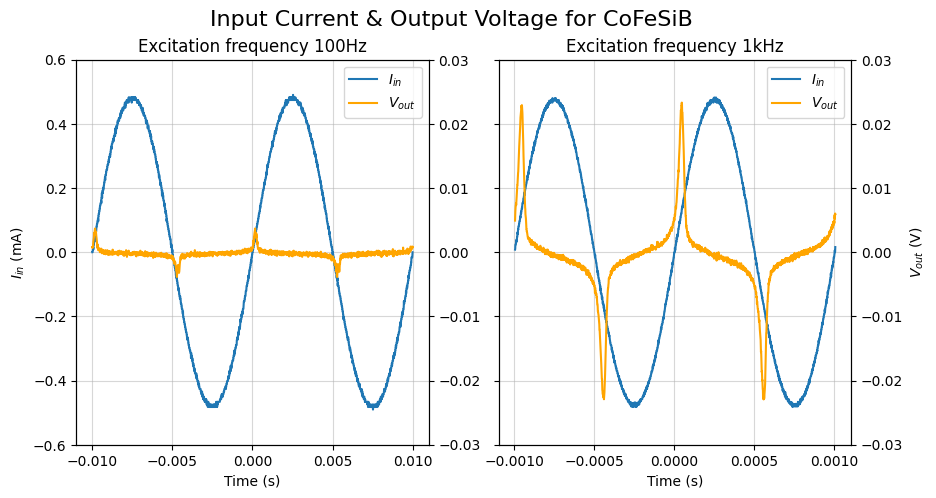

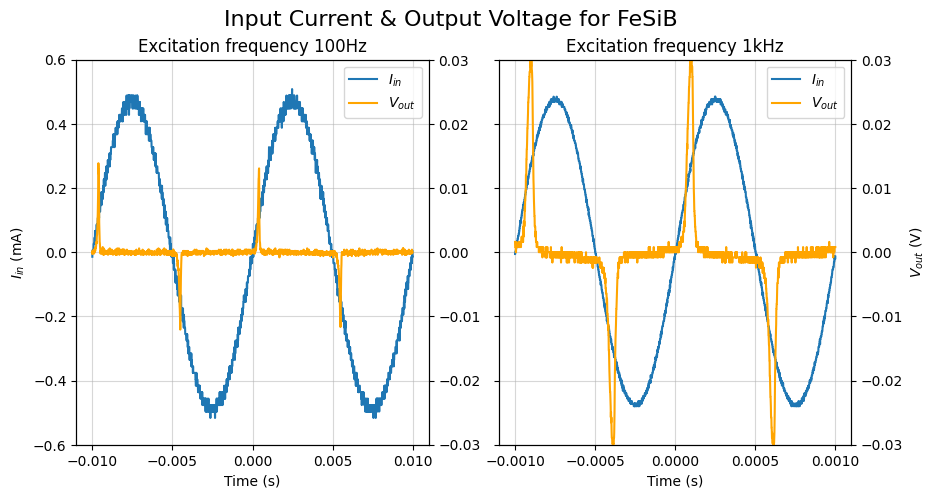

In [8]:
import os
import glob
from os.path import basename
from scipy import integrate

dfs = []

for f in glob.glob(path + '*Hz.csv'):
    (v, *freq) = basename(f).split('_')
    freq = freq[0].split('Hz')[0]
    df = pd.read_csv(f, names=['Time', 'Vin', 'Vout'], skiprows=1)
    df['Iin'] = df['Vin'] / 1000 * 1000
    df['Vout_avg'] = df['Vout'] - df['Vout'].mean()
    df['Vout_int'] = integrate.cumulative_trapezoid(
        df['Vout_avg'], df['Time'], initial=0
    )
    material = 'CoFeSiB' if v == '1' else 'FeSiB'
    dfs += [
        {'material': material, 'freq': freq, 'df': df}
    ]

dfs.sort(key=lambda x: (x['freq'], x['material']))

for material in ['CoFeSiB', 'FeSiB']:
    dfs_of_material = [d for d in dfs if d['material'] == material]
    fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
    axs_iter = iter(axs.flatten())
    for d in dfs_of_material:
        ax = next(axs_iter)
        df = d['df']
        ax.plot(df['Time'], df['Iin'], label='$I_{in}$')
        ax2 = ax.twinx()
        ax2.plot(df['Time'], df['Vout'], label='$V_{out}$', color='orange')
        ax.set_ylim(-0.6, 0.6)
        ax2.set_ylim(-0.03, 0.03)
        ax.set_xlabel('Time (s)')
        ax.set_title(f'Excitation frequency {d['freq']}Hz')
        ax.grid(True, alpha=0.5)
        lines1, labels1 = ax.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax.legend(lines1 + lines2, labels1 + labels2)
        if ax is axs[0]:
            ax.set_ylabel('$I_{in}$ (mA)')
        if ax is axs[1]:
            ax2.set_ylabel('$V_{out}$ (V)')

    fig.suptitle(f'Input Current & Output Voltage for {material}', fontsize=16)

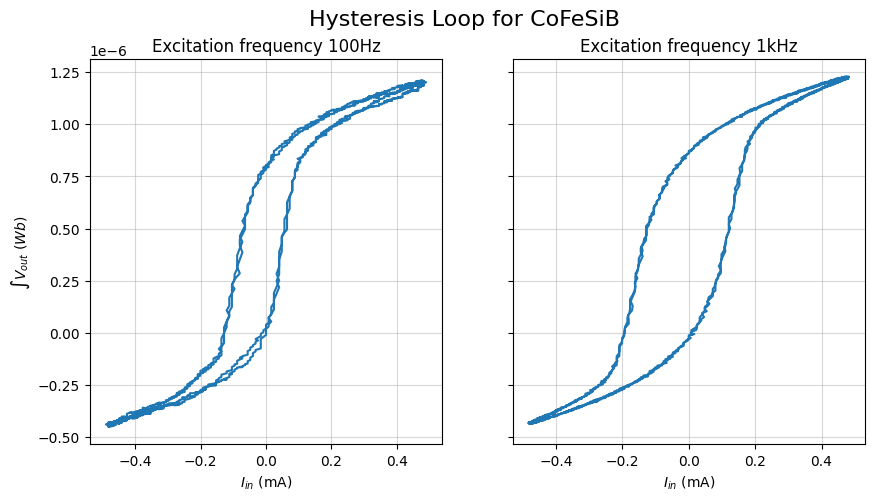

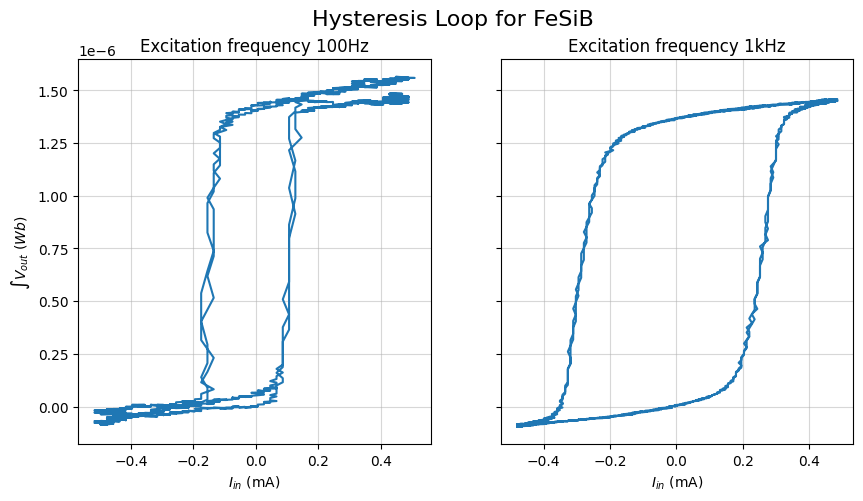

In [9]:
for material in ['CoFeSiB', 'FeSiB']:
    dfs_of_material = [d for d in dfs if d['material'] == material]
    fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
    axs_iter = iter(axs.flatten())
    for d in dfs_of_material:
        ax = next(axs_iter)
        df = d['df']
        ax.plot(df['Iin'], df['Vout_int'])
        ax.set_xlabel('$I_{in}$ (mA)')
        ax.set_ylabel(r'$\int{V_{out}} \ (Wb)$')
        ax.set_title(f'Excitation frequency {d['freq']}Hz')
        ax.grid(True, alpha=0.5)
        if ax is axs[1]:
            ax.set_ylabel('')

    fig.suptitle(f'Hysteresis Loop for {material}', fontsize=16)

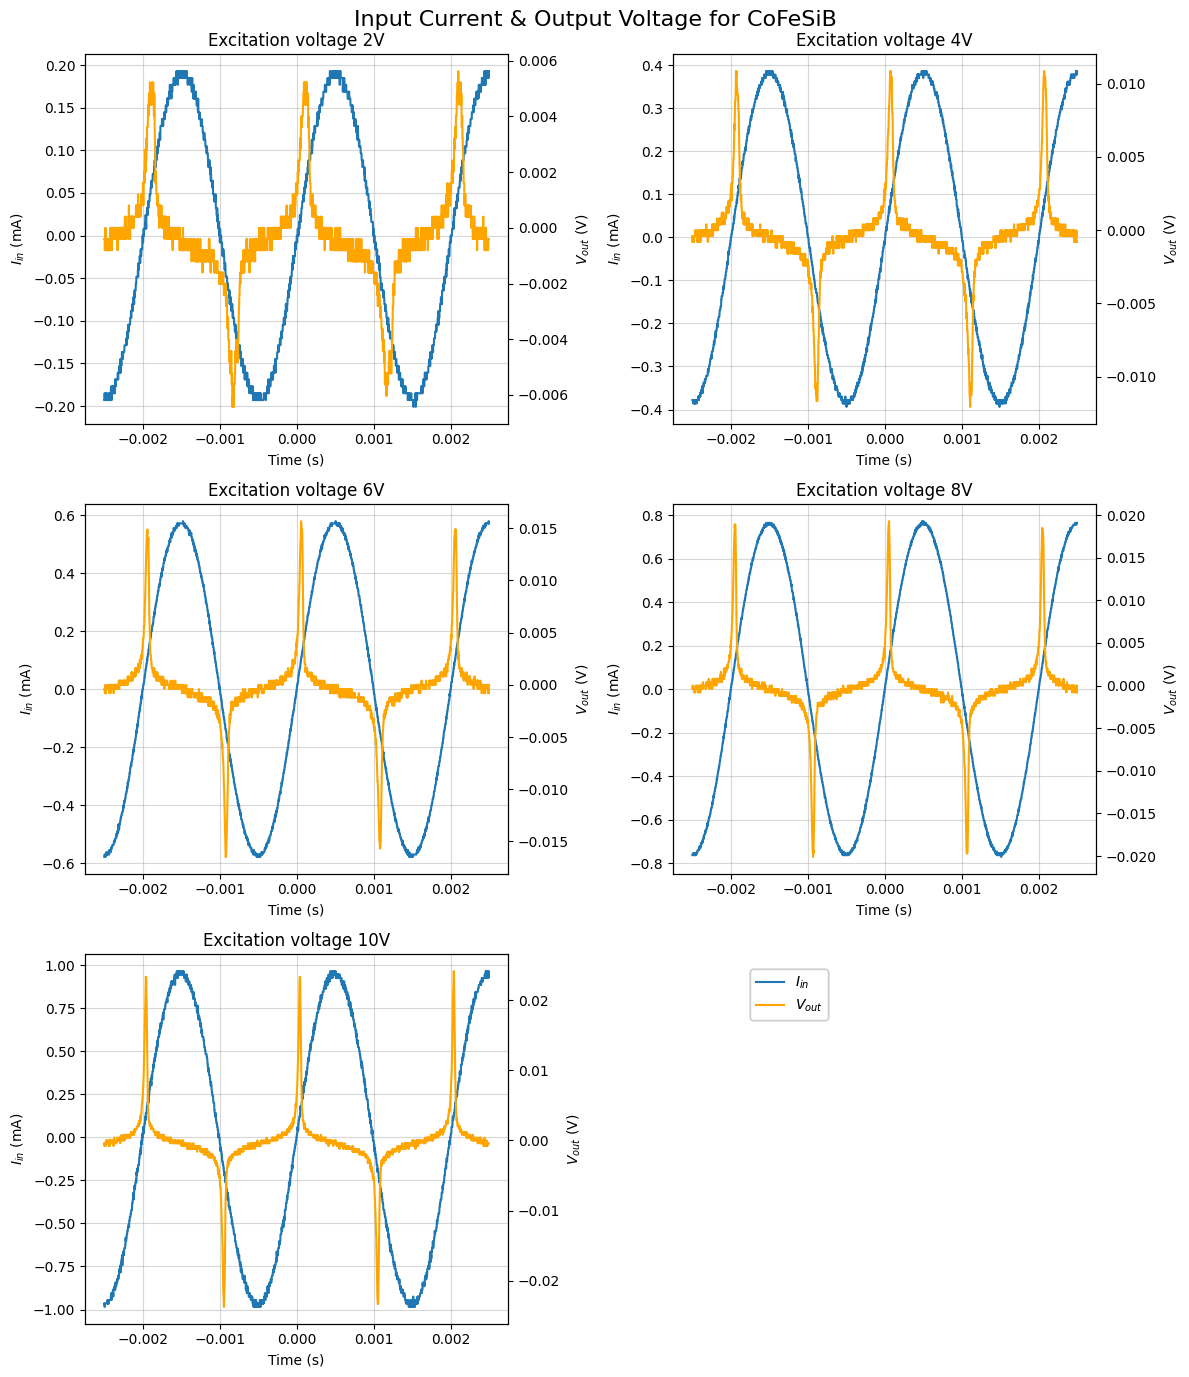

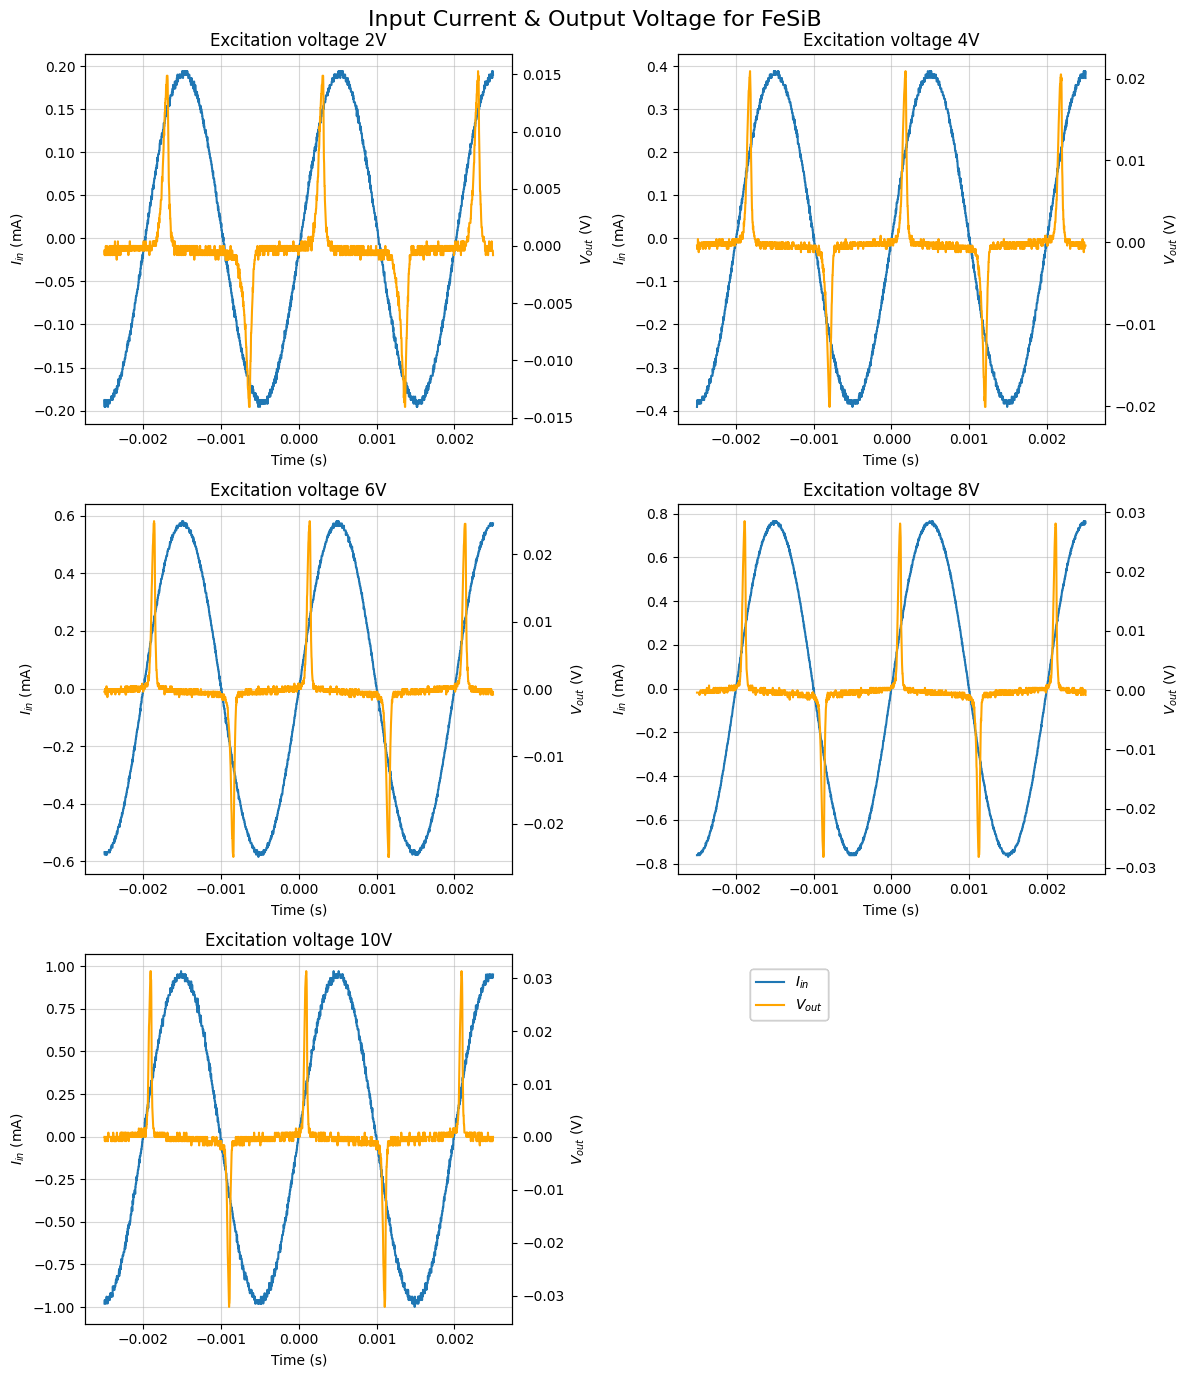

In [10]:
import os
import glob
from os.path import basename

dfs = []

for f in glob.glob(path + '*V.csv'):
    (v, *volts) = basename(f).split('_')
    volts = volts[0].split('V')[0]
    df = pd.read_csv(f, names=['Time', 'Vin', 'Vout'], skiprows=1)
    df['Iin'] = df['Vin'] / 1000 * 1000
    material = 'CoFeSiB' if v == '2' else 'FeSiB'
    dfs += [
        {'material': material, 'volts': volts, 'df': df}
    ]

dfs.sort(key=lambda x: (float(x['volts']), x['material']))

for material in ['CoFeSiB', 'FeSiB']:
    dfs_of_material = [d for d in dfs if d['material'] == material]
    fig, axs = plt.subplots(3, 2, figsize=(12, 14))
    axs_iter = iter(axs.flatten())
    for d in dfs_of_material:
        ax = next(axs_iter)
        df = d['df']
        ax.plot(df['Time'], df['Iin'], label='$I_{in}$')
        ax2 = ax.twinx()
        ax2.plot(df['Time'], df['Vout'], label='$V_{out}$', color='orange')
        ax.set(xlabel='Time (s)', ylabel='$I_{in}$ (mA)')
        ax2.set_ylabel('$V_{out}$ (V)')
        ax.set_title(f'Excitation voltage {d['volts']}V')
        ax.grid(True, alpha=0.5)
        lines1, labels1 = ax.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        fig.legend(lines1 + lines2, labels1 + labels2, bbox_to_anchor=(0.7, 0.3))

    fig.delaxes(axs[2,1])
    fig.subplots_adjust(top=0.9)
    fig.suptitle(f'Input Current & Output Voltage for {material}', fontsize=16)
    fig.tight_layout()

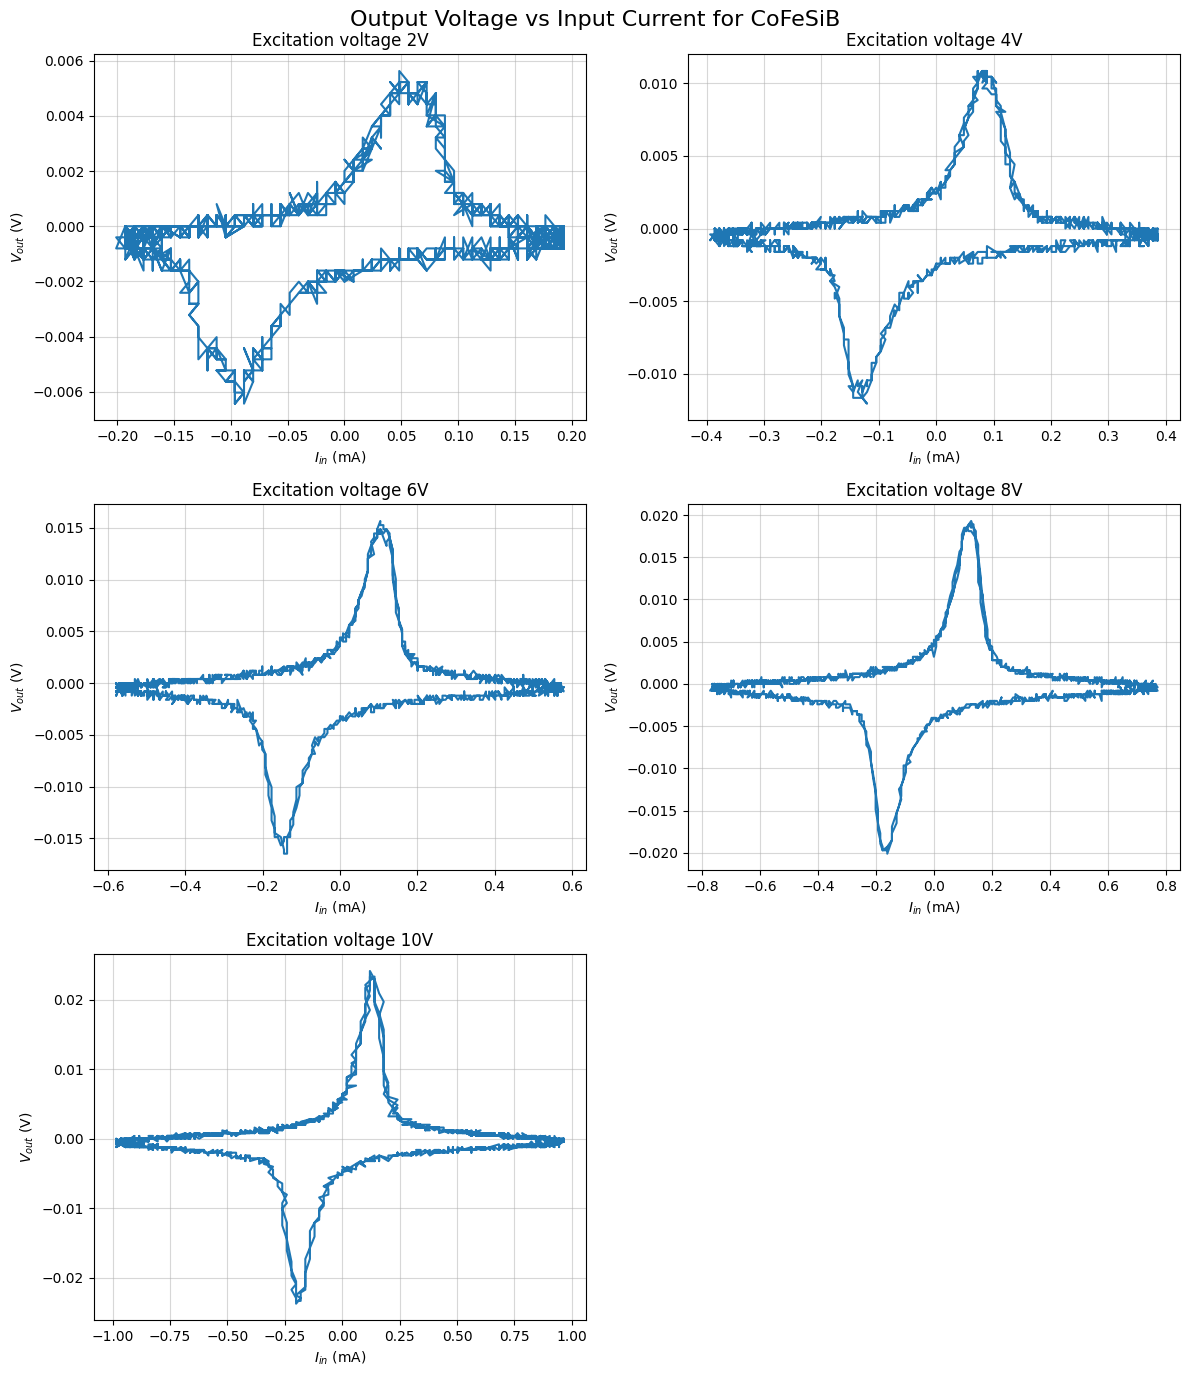

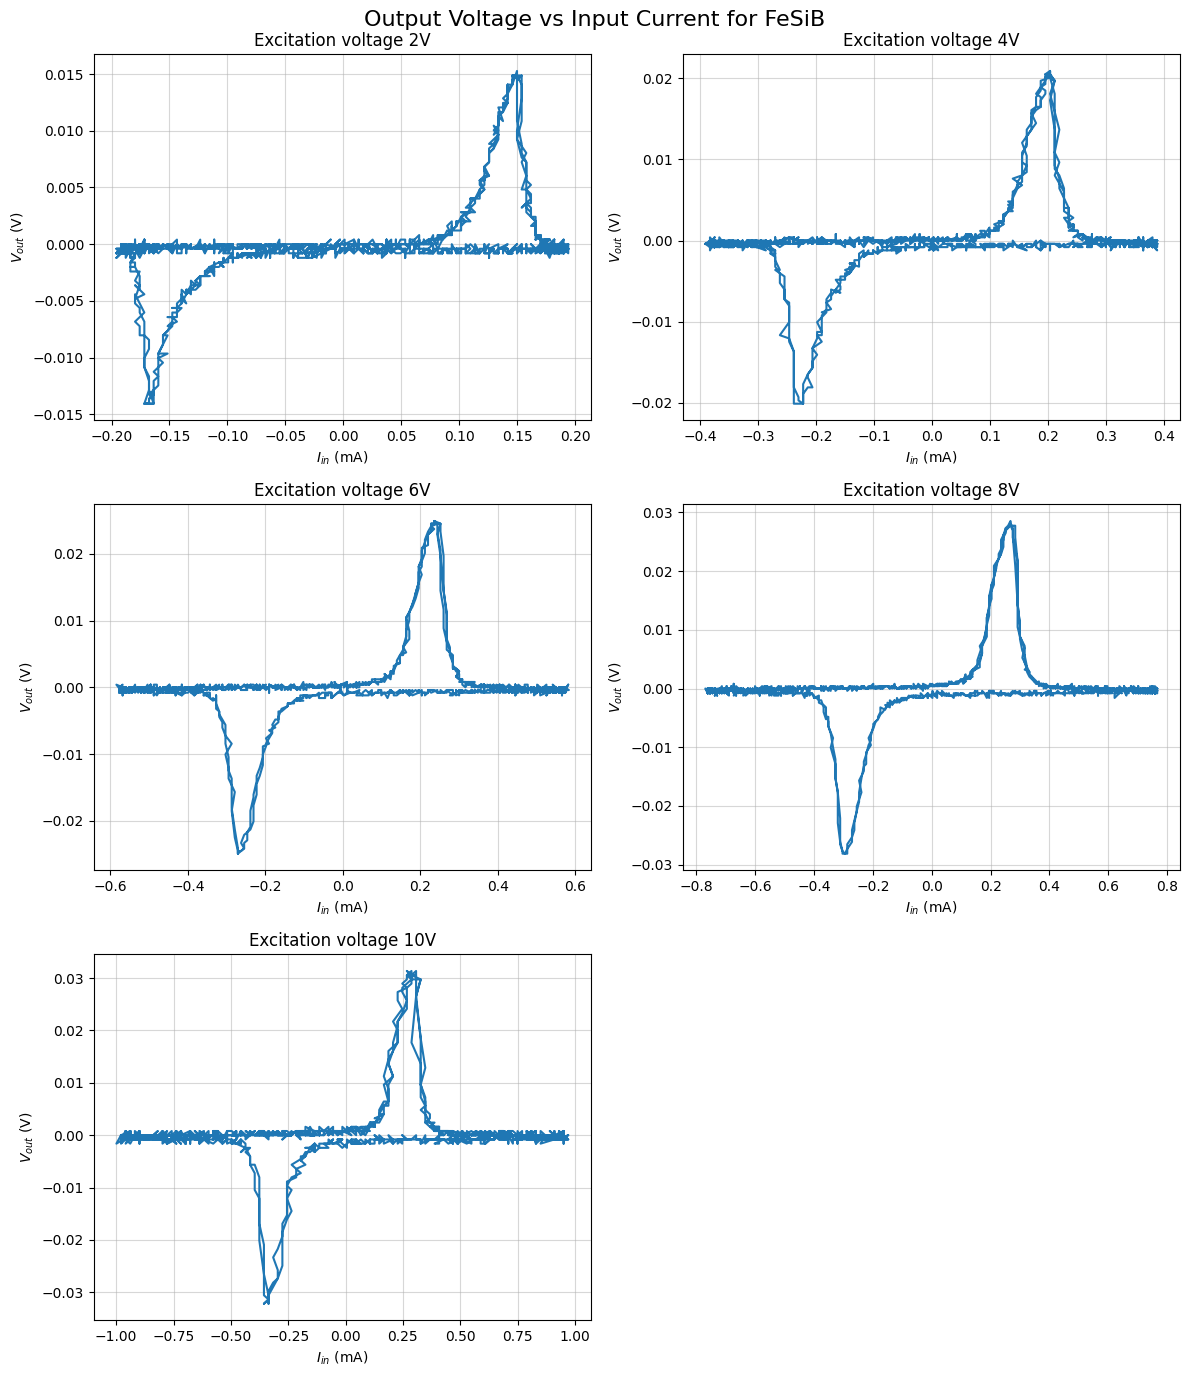

In [7]:
for material in ['CoFeSiB', 'FeSiB']:
    dfs_of_material = [d for d in dfs if d['material'] == material]
    fig, axs = plt.subplots(3, 2, figsize=(12, 14))
    axs_iter = iter(axs.flatten())
    for d in dfs_of_material:
        ax = next(axs_iter)
        df = d['df']
        ax.plot(df['Iin'], df['Vout'], label='$I_{in}$')
        ax.set(xlabel='$I_{in}$ (mA)', ylabel='$V_{out}$ (V)')
        ax.set_title(f'Excitation voltage {d['volts']}V')
        ax.grid(True, alpha=0.5)

    fig.delaxes(axs[2,1])
    fig.subplots_adjust(top=0.9)
    fig.suptitle(f'Output Voltage vs Input Current for {material}', fontsize=16)
    fig.tight_layout()